# Lucrarea de laborator 1 — Ingestie și analiză Big Data cu DWH streaming și dashboarduri

## 1. Ingestia și stocarea datelor

### Configurarea mediului de lucru
`JAVA_HOME` (OpenJDK din env), interpretorul Python pentru Spark și verifică directoarele.

#### Crearea sesiunii Spark cu Delta Lake

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.lab_common import *          # căi + constante
spark = get_spark(app="yelp-lab1", kafka=True)
PARQUET_DIR = DATA_DIR / "parquet"
PARQUET_PART_DIR = DATA_DIR / "parquet_partitioned"
SOURCE_NAME = "yelp_academic_dataset_review.json"
RAW_FILE = RAW_DIR / SOURCE_NAME
print(spark.version, spark.conf.get("spark.jars.packages"))

:: loading settings :: url = jar:file:/home/ivan/.mamba/envs/Playground/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/ivan/.ivy2.5.2/cache
The jars for the packages stored in: /home/ivan/.ivy2.5.2/jars
io.delta#delta-spark_4.1_2.13 added as a dependency
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-d76348eb-57aa-4ace-b68a-b46841403363;1.0
	confs: [default]
	found io.delta#delta-spark_4.1_2.13;4.4.0 in central
	found io.delta#delta-storage;4.4.0 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.

4.1.1 io.delta:delta-spark_4.1_2.13:4.4.0,org.apache.spark:spark-sql-kafka-0-10_2.13:4.1.1


### Verificări: Python worker și Delta Lake

In [2]:
resultat = (
    spark.sparkContext
    .parallelize([1, 2, 3], 2)
    .map(lambda x: x * 10)
    .collect()
)
assert resultat == [10, 20, 30]
print("PYTHON WORKER: PASS")

test_delta = str(DATA_DIR / "_delta_smoke_test")
spark.range(3).write.format("delta").mode("overwrite").save(test_delta)
assert spark.read.format("delta").load(test_delta).count() == 3
print("DELTA LAKE: PASS")

PYTHON WORKER: PASS


26/10/14 07:29:43 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


DELTA LAKE: PASS


### Încărcarea JSON cu schemă explicită
Fișierul Yelp este **JSON Lines** (un obiect JSON pe linie). Schema este definită explicit (fără `inferSchema`).  
Câmpul `date` are formatul `yyyy-MM-dd HH:mm:ss` și este citit direct ca `TimestampType`. Adăugăm coloana derivată `year`, folosită la filtrare și ca și coloană de partiționare.

In [20]:
from pyspark.sql import functions as F
from pyspark.sql import types as T

review_schema = T.StructType([
    T.StructField("review_id",   T.StringType(),    True),
    T.StructField("user_id",     T.StringType(),    True),
    T.StructField("business_id", T.StringType(),    True),
    T.StructField("stars",       T.DoubleType(),    True),
    T.StructField("useful",      T.LongType(),      True),
    T.StructField("funny",       T.LongType(),      True),
    T.StructField("cool",        T.LongType(),      True),
    T.StructField("text",        T.StringType(),    True),
    T.StructField("date",        T.TimestampType(), True),
])

def read_source():
    return (
        spark.read
        .schema(review_schema)
        .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
        .json(str(RAW_DIR))
        .withColumn("year", F.year("date"))
    )

df_src = read_source()
df_src.printSchema()
df_src.show(5, truncate=50)

root
 |-- review_id: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- business_id: string (nullable = true)
 |-- stars: double (nullable = true)
 |-- useful: long (nullable = true)
 |-- funny: long (nullable = true)
 |-- cool: long (nullable = true)
 |-- text: string (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- year: integer (nullable = true)

+----------------------+----------------------+----------------------+-----+------+-----+----+--------------------------------------------------+-------------------+----+
|             review_id|               user_id|           business_id|stars|useful|funny|cool|                                              text|               date|year|
+----------------------+----------------------+----------------------+-----+------+-----+----+--------------------------------------------------+-------------------+----+
|KU_O5udG6zpxOg-VcAEodg|mh_-eMZ6K5RLWhZyISBhwA|XQfwVwDr-v0ZS3_CbbE5Xw|  3.0|     0|    0|   0|If you dec

In [21]:
n_src = df_src.count()
n_bad_dates = df_src.filter(F.col("date").isNull()).count()
print(f"Număr total de rânduri: {n_src:,}")
print(f"Rânduri cu date nulă (verificare format timestamp): {n_bad_dates:,}")

Număr total de rânduri: 6,990,291
Rânduri cu date nulă (verificare format timestamp): 151


#### Interogările comune (aceleași pentru toate formatele)
- **Filtrare:** recenziile de 5 stele din anul 2019 → `count()`
- **Agregare:** pentru anii ≥ 2015: numărul de recenzii, media stelelor și media voturilor `useful` pe an → `collect()`

In [22]:
FILTER_YEAR = 2019
AGG_FROM_YEAR = 2015

def q_filter(df):
    return df.filter((F.col("year") == FILTER_YEAR) & (F.col("stars") == 5.0))

def q_agg(df):
    return (
        df.filter(F.col("year") >= AGG_FROM_YEAR)
          .groupBy("year")
          .agg(F.count("*").alias("n_reviews"),
               F.round(F.avg("stars"), 3).alias("avg_stars"),
               F.round(F.avg("useful"), 3).alias("avg_useful"))
          .orderBy("year")
    )

print(f"Filtrare (year={FILTER_YEAR}, stars=5):", f"{q_filter(df_src).count():,}")
q_agg(df_src).show()

Filtrare (year=2019, stars=5): 463,911
+----+---------+---------+----------+
|year|n_reviews|avg_stars|avg_useful|
+----+---------+---------+----------+
|2015|   688412|    3.742|     1.278|
|2016|   758870|    3.766|     1.176|
|2017|   820036|    3.779|     1.035|
|2018|   906347|    3.781|     1.002|
|2019|   907245|    3.767|     0.953|
|2020|   554548|    3.783|       1.0|
|2021|   618162|    3.705|     0.858|
|2022|    31665|    3.705|     0.636|
+----+---------+---------+----------+



#### Funcții ajutătoare: dimensiune pe disc și măsurarea timpului

In [23]:
import pandas as pd
from time import perf_counter
from statistics import median

MB = 1024 ** 2
REPEATS = 3
INCLUDE_FULL_SCAN = True   # citire completă a tuturor coloanelor (vezi nota de mai jos)

def dir_size(path):
    """Dimensiunea totală (bytes) a unui fișier/director, recursiv (urmează symlink-urile de fișiere)."""
    path = Path(path)
    if path.is_file():
        return path.stat().st_size
    total = 0
    for root, _, files in os.walk(path):
        for f in files:
            total += os.path.getsize(os.path.join(root, f))
    return total

def measure(operation, repeats=REPEATS):
    times = []
    for _ in range(repeats):
        start = perf_counter()
        operation()  # count() sau collect()
        times.append(perf_counter() - start)
    return times, median(times)

SIZES = {}
RESULTS = {}

def benchmark(label, reader, repeats=REPEATS):
    ops = {
        "read_count":   lambda: reader().count(),
        "filter_count": lambda: q_filter(reader()).count(),
        "agg_collect":  lambda: q_agg(reader()).collect(),
    }
    if INCLUDE_FULL_SCAN:
        ops["read_full"] = lambda: reader().write.format("noop").mode("overwrite").save()
    res = {}
    for name, op in ops.items():
        times, med = measure(op, repeats)
        res[name] = {"times": times, "median": med}
        print(f"{label:<20} {name:<13} rulări={[round(t, 2) for t in times]}  mediană={med:.2f} s")
    RESULTS[label] = res
    return res

def results_table():
    rows = []
    for label, res in RESULTS.items():
        row = {"Format": label}
        for op, v in res.items():
            row[f"{op} (s)"] = round(v["median"], 3)
        rows.append(row)
    return pd.DataFrame(rows).set_index("Format")

> **Notă despre „citire”:** `count()` pe Parquet/Delta poate fi rezolvat aproape doar din metadate (footer Parquet / statistici din `_delta_log`), fără a citi coloanele. De aceea am adăugat și `read_full`: scriere în formatul `noop`, care forțează citirea și decodarea **tuturor** coloanelor fără a scrie nimic pe disc. Cerința din enunț (declanșare prin `count()`/`collect()`) este acoperită de `read_count`, `filter_count` și `agg_collect`.

In [24]:
SIZES["JSON (sursă)"] = dir_size(RAW_DIR)
print(f"Dimensiune sursă: {SIZES['JSON (sursă)'] / MB:,.1f} MB")
benchmark("JSON (sursă)", read_source);

Dimensiune sursă: 5,094.4 MB
JSON (sursă)         read_count    rulări=[4.16, 4.5, 4.24]  mediană=4.24 s
JSON (sursă)         filter_count  rulări=[5.28, 4.81, 4.84]  mediană=4.84 s
JSON (sursă)         agg_collect   rulări=[7.42, 6.98, 7.17]  mediană=7.17 s
JSON (sursă)         read_full     rulări=[9.15, 8.39, 8.73]  mediană=8.73 s


### Salvarea și recitirea datelor în Parquet

In [25]:
t0 = perf_counter()
df_src.write.mode("overwrite").parquet(str(PARQUET_DIR))
print(f"Scriere Parquet: {perf_counter() - t0:.1f} s")

def read_parquet():
    return spark.read.parquet(str(PARQUET_DIR))

df_pq = read_parquet()
df_pq.printSchema()

def schema_signature(df):
    return [(f.name, f.dataType.simpleString()) for f in df.schema.fields]

n_pq = df_pq.count()
assert n_pq == n_src, (n_pq, n_src)
assert schema_signature(df_pq) == schema_signature(df_src)
print(f"Rânduri Parquet = {n_pq:,} (identic cu sursa), schema corespunde: OK")

Scriere Parquet: 16.8 s
root
 |-- review_id: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- business_id: string (nullable = true)
 |-- stars: double (nullable = true)
 |-- useful: long (nullable = true)
 |-- funny: long (nullable = true)
 |-- cool: long (nullable = true)
 |-- text: string (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- year: integer (nullable = true)

Rânduri Parquet = 6,990,291 (identic cu sursa), schema corespunde: OK


### Compararea dimensiunilor și a timpului: sursă vs Parquet

In [26]:
SIZES["Parquet"] = dir_size(PARQUET_DIR)
src_mb, pq_mb = SIZES["JSON (sursă)"] / MB, SIZES["Parquet"] / MB
diff_mb = pq_mb - src_mb
pct = diff_mb / src_mb * 100
n_files = len(list(PARQUET_DIR.glob("*.parquet")))

print(f"Sursă JSON : {src_mb:,.1f} MB")
print(f"Parquet    : {pq_mb:,.1f} MB  ({n_files} fișiere .parquet, compresie snappy)")
print(f"Diferență  : {diff_mb:+,.1f} MB  ->  Parquet ocupă {abs(pct):.1f}% "
      f"{'mai puțin' if pct < 0 else 'mai mult'} decât sursa")

Sursă JSON : 5,094.4 MB
Parquet    : 2,876.0 MB  (40 fișiere .parquet, compresie snappy)
Diferență  : -2,218.4 MB  ->  Parquet ocupă 43.5% mai puțin decât sursa


In [27]:
benchmark("Parquet", read_parquet)
results_table()

Parquet              read_count    rulări=[0.13, 0.1, 0.09]  mediană=0.10 s
Parquet              filter_count  rulări=[0.2, 0.13, 0.14]  mediană=0.14 s
Parquet              agg_collect   rulări=[0.35, 0.29, 0.28]  mediană=0.29 s
Parquet              read_full     rulări=[4.07, 4.03, 4.48]  mediană=4.07 s


,read_count (s),filter_count (s),agg_collect (s),read_full (s)
Format,,,,
JSON (sursă),4.236,4.841,7.167,8.727
Parquet,0.101,0.137,0.292,4.067


### Parquet partiționat
Coloana de partiționare: **`year`** (~18 valori distincte, 2005–2022) — nu este identificator unic, iar interogările noastre filtrează după ea.  
`repartition("year")` înainte de scriere produce un singur fișier per partiție (evită multe fișiere mici).

In [28]:
t0 = perf_counter()
(df_src.repartition("year")
       .write.mode("overwrite")
       .partitionBy("year")
       .parquet(str(PARQUET_PART_DIR)))
print(f"Scriere Parquet partiționat: {perf_counter() - t0:.1f} s")

def read_parquet_part():
    return spark.read.parquet(str(PARQUET_PART_DIR))

df_pq_part = read_parquet_part()
assert df_pq_part.count() == n_src
assert schema_signature(df_pq_part) == schema_signature(df_src)
SIZES["Parquet partiționat"] = dir_size(PARQUET_PART_DIR)
print(f"Dimensiune: {SIZES['Parquet partiționat'] / MB:,.1f} MB")

Scriere Parquet partiționat: 25.3 s
Dimensiune: 2,871.5 MB


In [29]:
benchmark("Parquet partiționat", read_parquet_part)
results_table()

Parquet partiționat  read_count    rulări=[0.14, 0.09, 0.09]  mediană=0.09 s
Parquet partiționat  filter_count  rulări=[0.1, 0.1, 0.1]  mediană=0.10 s
Parquet partiționat  agg_collect   rulări=[0.25, 0.27, 0.27]  mediană=0.27 s
Parquet partiționat  read_full     rulări=[4.29, 4.14, 4.31]  mediană=4.29 s


,read_count (s),filter_count (s),agg_collect (s),read_full (s)
Format,,,,
JSON (sursă),4.236,4.841,7.167,8.727
Parquet,0.101,0.137,0.292,4.067
Parquet partiționat,0.091,0.098,0.268,4.294


### Verificarea partițiilor și `PartitionFilters`
Fiecare valoare distinctă a coloanei `year` devine un director `year=<valoare>`. Valoarea **nu mai este stocată în fișierele Parquet** — Spark o reconstruiește din numele directorului (partition discovery).

In [30]:
for d in sorted(PARQUET_PART_DIR.glob("year=*")):
    print(d.name)

year=2005
year=2006
year=2007
year=2008
year=2009
year=2010
year=2011
year=2012
year=2013
year=2014
year=2015
year=2016
year=2017
year=2018
year=2019
year=2020
year=2021
year=2022
year=__HIVE_DEFAULT_PARTITION__


In [34]:
n = 'year=__HIVE_DEFAULT_PARTITION__'
0 if '__HIVE_' in n else 1

0

In [37]:
part_rows = []
for d in sorted(PARQUET_PART_DIR.glob("year=*")):
    files = list(d.glob("*.parquet"))
    if 'year=__HIVE_DEFAULT_PARTITION__' in d.name: continue
    part_rows.append({"director": d.name,
                      "year": int(d.name.split("=")[1]),
                      "fișiere .parquet": len(files),
                      "MB": round(dir_size(d) / MB, 1)})
df_parts = pd.DataFrame(part_rows).set_index("year")

counts = {r["year"]: r["count"] for r in df_pq_part.groupBy("year").count().collect()}
df_parts["rânduri"] = df_parts.index.map(counts)
df_parts

,director,fișiere .parquet,MB,rânduri
year,,,,
2005,year=2005,1,0.3,854
2006,year=2006,1,1.6,3853
2007,year=2007,1,7.2,15363
2008,year=2008,1,25.5,48224
2009,year=2009,1,38.8,74386
2010,year=2010,1,70.4,138584
2011,year=2011,1,115.4,230809
2012,year=2012,1,139.7,286569
2013,year=2013,1,179.5,383942


In [38]:
# legătura rând -> fișier: calea fișierului conține valoarea partiției
(df_pq_part.filter(F.col("year").isin(2010, 2019))
    .select("review_id", "year", F.col("_metadata.file_path").alias("file_path"))
    .dropDuplicates(["year"])
    .show(truncate=False))

# un fișier dintr-o partiție, citit direct: NU conține coloana year
one_file = next((PARQUET_PART_DIR / f"year={FILTER_YEAR}").glob("*.parquet"))
print("Coloane în fișierul fizic:", spark.read.parquet(str(one_file)).columns)

+----------------------+----+---------------------------------------------------------------------------------------------------------------------------------------------------+
|review_id             |year|file_path                                                                                                                                          |
+----------------------+----+---------------------------------------------------------------------------------------------------------------------------------------------------+
|KLTBA1sx5yQVIrb_I6R8FA|2010|file:/home/ivan/tmp/new/big_data/laborator_1/data/parquet_partitioned/year=2010/part-00008-06fcdf24-7ae7-4994-88e6-cef789855520.c000.snappy.parquet|
|F6VdYuJiefNBfn3HNELv0A|2019|file:/home/ivan/tmp/new/big_data/laborator_1/data/parquet_partitioned/year=2019/part-00007-06fcdf24-7ae7-4994-88e6-cef789855520.c000.snappy.parquet|
+----------------------+----+---------------------------------------------------------------------------------

In [39]:
import io
import contextlib

def explain_str(df, mode="formatted"):
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df.explain(mode)
    return buf.getvalue()

def show_scan_info(title, df):
    plan = explain_str(q_filter(df))
    print("=" * 100)
    print(title)
    print("=" * 100)
    print(plan)
    print("--- extras din nodul Scan ---")
    for line in plan.splitlines():
        if any(k in line for k in ("PartitionFilters", "PushedFilters", "ReadSchema")):
            print("   ", line.strip())
    return plan

plan_pq = show_scan_info("Parquet NEpartiționat", read_parquet())

Parquet NEpartiționat
== Physical Plan ==
* Filter (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [10]: [review_id#4313, user_id#4314, business_id#4315, stars#4316, useful#4317L, funny#4318L, cool#4319L, text#4320, date#4321, year#4322]
Batched: true
Location: InMemoryFileIndex [file:/home/ivan/tmp/new/big_data/laborator_1/data/parquet]
PushedFilters: [IsNotNull(year), IsNotNull(stars), EqualTo(year,2019), EqualTo(stars,5.0)]
ReadSchema: struct<review_id:string,user_id:string,business_id:string,stars:double,useful:bigint,funny:bigint,cool:bigint,text:string,date:timestamp,year:int>

(2) ColumnarToRow [codegen id : 1]
Input [10]: [review_id#4313, user_id#4314, business_id#4315, stars#4316, useful#4317L, funny#4318L, cool#4319L, text#4320, date#4321, year#4322]

(3) Filter [codegen id : 1]
Input [10]: [review_id#4313, user_id#4314, business_id#4315, stars#4316, useful#4317L, funny#4318L, cool#4319L, text#4320, date#4321, year#4322]
Condition : (((isnotnull(

In [40]:
plan_pq_part = show_scan_info("Parquet PARTIȚIONAT", read_parquet_part())
assert "PartitionFilters: [" in plan_pq_part and "year" in plan_pq_part.split("PartitionFilters:")[1].split("\n")[0]
print("\nPartitionFilters conține condiția pe `year` -> partition pruning activ.")

Parquet PARTIȚIONAT
== Physical Plan ==
* Filter (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [10]: [review_id#4324, user_id#4325, business_id#4326, stars#4327, useful#4328L, funny#4329L, cool#4330L, text#4331, date#4332, year#4333]
Batched: true
Location: InMemoryFileIndex [file:/home/ivan/tmp/new/big_data/laborator_1/data/parquet_partitioned]
PartitionFilters: [isnotnull(year#4333), (year#4333 = 2019)]
PushedFilters: [IsNotNull(stars), EqualTo(stars,5.0)]
ReadSchema: struct<review_id:string,user_id:string,business_id:string,stars:double,useful:bigint,funny:bigint,cool:bigint,text:string,date:timestamp>

(2) ColumnarToRow [codegen id : 1]
Input [10]: [review_id#4324, user_id#4325, business_id#4326, stars#4327, useful#4328L, funny#4329L, cool#4330L, text#4331, date#4332, year#4333]

(3) Filter [codegen id : 1]
Input [10]: [review_id#4324, user_id#4325, business_id#4326, stars#4327, useful#4328L, funny#4329L, cool#4330L, text#4331, date#4332, year#4333]


**Interpretare:**
- La Parquet **nepartiționat**, condiția `year = 2019` apare doar în `PushedFilters` / `Filter`: Spark deschide toate fișierele și folosește statisticile min/max din row groups pentru a sări peste o parte din date.
- La Parquet **partiționat**, condiția apare în `PartitionFilters`: Spark elimină directoarele `year≠2019` încă din faza de planificare (partition pruning) și citește doar `year=2019/`. `PushedFilters` rămâne doar pentru `stars = 5.0`.

### Tabel Delta partiționat
Directorul Delta se șterge înainte de scriere, pentru ca **versiunea 0** să fie exact încărcarea inițială (la rulări repetate, `overwrite` ar crea o versiune nouă, nu v0).

In [41]:
import shutil
shutil.rmtree(DELTA_DIR, ignore_errors=True)

t0 = perf_counter()
(df_src.repartition("year")
       .write.format("delta")
       .mode("overwrite")
       .partitionBy("year")
       .save(str(DELTA_DIR)))
print(f"Scriere Delta: {perf_counter() - t0:.1f} s")

def read_delta():
    return spark.read.format("delta").load(str(DELTA_DIR))

df_delta = read_delta()
df_delta.printSchema()
n_delta_v0 = df_delta.count()
assert n_delta_v0 == n_src
assert schema_signature(df_delta) == schema_signature(df_src)
SIZES["Delta Lake"] = dir_size(DELTA_DIR)
print(f"Rânduri Delta = {n_delta_v0:,}, schema OK, dimensiune = {SIZES['Delta Lake'] / MB:,.1f} MB")

Scriere Delta: 28.9 s
root
 |-- review_id: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- business_id: string (nullable = true)
 |-- stars: double (nullable = true)
 |-- useful: long (nullable = true)
 |-- funny: long (nullable = true)
 |-- cool: long (nullable = true)
 |-- text: string (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- year: integer (nullable = true)

Rânduri Delta = 6,990,291, schema OK, dimensiune = 2,871.3 MB


In [42]:
benchmark("Delta Lake", read_delta)
results_table()

Delta Lake           read_count    rulări=[0.17, 0.15, 0.17]  mediană=0.17 s
Delta Lake           filter_count  rulări=[0.42, 0.24, 0.21]  mediană=0.24 s
Delta Lake           agg_collect   rulări=[1.05, 0.43, 0.44]  mediană=0.44 s
Delta Lake           read_full     rulări=[4.8, 4.07, 4.19]  mediană=4.19 s


,read_count (s),filter_count (s),agg_collect (s),read_full (s)
Format,,,,
JSON (sursă),4.236,4.841,7.167,8.727
Parquet,0.101,0.137,0.292,4.067
Parquet partiționat,0.091,0.098,0.268,4.294
Delta Lake,0.167,0.242,0.445,4.191


In [43]:
plan_delta = show_scan_info("Delta Lake (partiționat)", read_delta())

Delta Lake (partiționat)
== Physical Plan ==
* Filter (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [10]: [review_id#7145, user_id#7146, business_id#7147, stars#7148, useful#7149L, funny#7150L, cool#7151L, text#7152, date#7153, year#7154]
Batched: true
Location: PreparedDeltaFileIndex [file:/home/ivan/tmp/new/big_data/laborator_1/data/delta]
PartitionFilters: [isnotnull(year#7154), (year#7154 = 2019)]
PushedFilters: [IsNotNull(stars), EqualTo(stars,5.0)]
ReadSchema: struct<review_id:string,user_id:string,business_id:string,stars:double,useful:bigint,funny:bigint,cool:bigint,text:string,date:timestamp>

(2) ColumnarToRow [codegen id : 1]
Input [10]: [review_id#7145, user_id#7146, business_id#7147, stars#7148, useful#7149L, funny#7150L, cool#7151L, text#7152, date#7153, year#7154]

(3) Filter [codegen id : 1]
Input [10]: [review_id#7145, user_id#7146, business_id#7147, stars#7148, useful#7149L, funny#7150L, cool#7151L, text#7152, date#7153, year#7154]
Cond

### Inspectarea fișierelor Delta

In [44]:
import json
from collections import Counter

LOG_DIR = DELTA_DIR / "_delta_log"
data_files = [p for p in DELTA_DIR.rglob("*.parquet") if "_delta_log" not in p.parts]

print("Conținut director Delta:")
for p in sorted(DELTA_DIR.iterdir())[:6]:
    print("  ", p.name + ("/" if p.is_dir() else ""))
print("   ...")
print(f"Directoare de partiții : {len(list(DELTA_DIR.glob('year=*')))}")
print(f"Fișiere de date Parquet: {len(data_files)}  ({sum(f.stat().st_size for f in data_files) / MB:,.1f} MB)")
print(f"Exemplu fișier de date : {data_files[0].relative_to(DELTA_DIR)}")
print("\n_delta_log:")
for p in sorted(LOG_DIR.iterdir()):
    print(f"   {p.name:<45} {p.stat().st_size:>10,} B")

Conținut director Delta:
   _delta_log/
   year=2005/
   year=2006/
   year=2007/
   year=2008/
   year=2009/
   ...
Directoare de partiții : 19
Fișiere de date Parquet: 19  (2,849.0 MB)
Exemplu fișier de date : year=2018/part-00002-b29ec148-2e13-4327-bc81-1a53e0846ca1.c000.snappy.parquet

_delta_log:
   .00000000000000000000.crc.crc                        168 B
   .00000000000000000000.json.crc                       160 B
   00000000000000000000.crc                          20,455 B
   00000000000000000000.json                         19,333 B
   _staged_commits                                    4,096 B


In [45]:
with open(LOG_DIR / "00000000000000000000.json") as f:
    actions = [json.loads(line) for line in f]

print("Acțiuni în commit-ul 0:", dict(Counter(next(iter(a)) for a in actions)))
commit = next(a["commitInfo"] for a in actions if "commitInfo" in a)
print("Operație:", commit["operation"], "|", commit.get("operationParameters"))
meta = next(a["metaData"] for a in actions if "metaData" in a)
print("Coloane de partiționare:", meta["partitionColumns"])

first_add = next(a["add"] for a in actions if "add" in a)
print("\nExemplu acțiune `add`:")
print("  path           :", first_add["path"])
print("  partitionValues:", first_add["partitionValues"])
print("  size           :", f"{first_add['size']:,} B")
print("  stats          :", first_add["stats"][:250], "...")

# fișierele de date Delta sunt fișiere Parquet obișnuite
print("\nCitit direct ca Parquet:", spark.read.parquet(str(data_files[0])).count(), "rânduri")

Acțiuni în commit-ul 0: {'commitInfo': 1, 'metaData': 1, 'protocol': 1, 'add': 19}
Operație: WRITE | {'mode': 'Overwrite', 'partitionBy': '["year"]'}
Coloane de partiționare: ['year']

Exemplu acțiune `add`:
  path           : year=2005/part-00000-f54f113d-2c43-4677-93a3-e60ca8cc5291.c000.snappy.parquet
  partitionValues: {'year': '2005'}
  size           : 275,983 B
  stats          : {"numRecords":854,"minValues":{"review_id":"--noH3k3pKeCIa_UiRmGpw","user_id":"-2BsDZWzob5Q1ZGHcDJ6gw","business_id":"-KyQ_Bu21JNphNtxz-Jj-g","stars":1.0,"useful":0,"funny":0,"cool":0,"text":"# 1936\r\n2017 S. Broad St.\r\nPhila","date":"2005-02-16T0 ...

Citit direct ca Parquet: 906347 rânduri


**Concluzie:** datele tabelului Delta sunt fișiere Parquet obișnuite (organizate în directoare `year=...`), iar `_delta_log/` conține commit-uri JSON numerotate (`00000000000000000000.json`, ...). Fiecare commit descrie acțiunile tranzacției (`add`/`remove` fișiere, `metaData`, `protocol`, `commitInfo`); starea tabelului la o versiune = rejucarea log-ului până la acea versiune.

### Crearea versiunilor Delta
| Versiune | Operație | Ce facem |
|---|---|---|
| v0 | WRITE (overwrite) | încărcarea inițială |
| v1 | WRITE (append) | adăugăm 5 recenzii noi, anul 2023 (partiție nouă) |
| v2 | UPDATE | 5 recenzii reale din 2012: `stars = 1.0`, `useful += 1000` |
| v3 | DELETE | ștergem toate recenziile din cel mai vechi an |

In [46]:
from datetime import datetime
from delta.tables import DeltaTable

dt = DeltaTable.forPath(spark, str(DELTA_DIR))

# ---------- v1: APPEND ----------
append_rows = [
    (f"LAB01_APPEND_{i:03d}", "LAB01_USER", "LAB01_BUSINESS", 4.0, 0, 0, 0,
     f"Recenzie adăugată în laborator #{i}", datetime(2023, 1, i, 12, 0, 0), 2023)
    for i in range(1, 6)
]
append_ids = [r[0] for r in append_rows]
df_append = spark.createDataFrame(append_rows, schema=read_delta().schema)
df_append.write.format("delta").mode("append").save(str(DELTA_DIR))

read_delta().filter(F.col("review_id").isin(append_ids)).select("review_id", "stars", "date", "year").show()
print("Partiție nouă creată:", (DELTA_DIR / "year=2023").exists())

+----------------+-----+-------------------+----+
|       review_id|stars|               date|year|
+----------------+-----+-------------------+----+
|LAB01_APPEND_005|  4.0|2023-01-05 12:00:00|2023|
|LAB01_APPEND_004|  4.0|2023-01-04 12:00:00|2023|
|LAB01_APPEND_001|  4.0|2023-01-01 12:00:00|2023|
|LAB01_APPEND_003|  4.0|2023-01-03 12:00:00|2023|
|LAB01_APPEND_002|  4.0|2023-01-02 12:00:00|2023|
+----------------+-----+-------------------+----+

Partiție nouă creată: True


In [47]:
# ---------- v2: UPDATE ----------
UPDATE_YEAR = 2012
update_ids = [r.review_id for r in (
    read_delta().filter((F.col("year") == UPDATE_YEAR) & (F.col("stars") != 1.0))
                .select("review_id").orderBy("review_id").limit(5).collect())]

print("Înainte de UPDATE:")
read_delta().filter(F.col("review_id").isin(update_ids)).select("review_id", "stars", "useful", "year").show()

dt.update(
    condition=(F.col("year") == UPDATE_YEAR) & F.col("review_id").isin(update_ids),
    set={"stars": F.lit(1.0), "useful": F.col("useful") + 1000},
)

print("După UPDATE:")
read_delta().filter(F.col("review_id").isin(update_ids)).select("review_id", "stars", "useful", "year").show()

Înainte de UPDATE:
+--------------------+-----+------+----+
|           review_id|stars|useful|year|
+--------------------+-----+------+----+
|--2aapBd7imcn5Kug...|  4.0|     0|2012|
|---hY_aTcGUhJT688...|  5.0|     1|2012|
|--3AB1jU10He29Cvh...|  4.0|     1|2012|
|---v3SgPiNYCHZa2f...|  4.0|     1|2012|
|--0abhSo7d0AdREbs...|  4.0|     0|2012|
+--------------------+-----+------+----+



26/10/14 08:02:37 WARN UpdateCommand: Could not validate number of records due to missing statistics.


După UPDATE:
+--------------------+-----+------+----+
|           review_id|stars|useful|year|
+--------------------+-----+------+----+
|--2aapBd7imcn5Kug...|  1.0|  1000|2012|
|---hY_aTcGUhJT688...|  1.0|  1001|2012|
|--3AB1jU10He29Cvh...|  1.0|  1001|2012|
|---v3SgPiNYCHZa2f...|  1.0|  1001|2012|
|--0abhSo7d0AdREbs...|  1.0|  1000|2012|
+--------------------+-----+------+----+



In [48]:
# ---------- v3: DELETE ----------
DELETE_YEAR = int(df_parts.index.min())        # cel mai vechi an din date
n_deleted = read_delta().filter(F.col("year") == DELETE_YEAR).count()
print(f"Rânduri din {DELETE_YEAR} înainte de DELETE: {n_deleted:,}")

dt.delete(F.col("year") == DELETE_YEAR)

print(f"Rânduri din {DELETE_YEAR} după DELETE   : {read_delta().filter(F.col('year') == DELETE_YEAR).count():,}")
print(f"Directorul year={DELETE_YEAR} încă există pe disc (necesar pentru time travel): "
      f"{(DELTA_DIR / f'year={DELETE_YEAR}').exists()}")

Rânduri din 2005 înainte de DELETE: 854
Rânduri din 2005 după DELETE   : 0
Directorul year=2005 încă există pe disc (necesar pentru time travel): True


### Istoricul și citirea versiunii 0 (time travel)

In [49]:
history = (dt.history()
             .select("version", "timestamp", "operation", "operationParameters", "operationMetrics")
             .orderBy("version"))
hist_pd = history.toPandas()
display(hist_pd[["version", "timestamp", "operation", "operationParameters"]])

print("Fișiere în _delta_log:", sorted(p.name for p in LOG_DIR.glob("*.json")))
assert list(hist_pd["operation"]) == ["WRITE", "WRITE", "UPDATE", "DELETE"], list(hist_pd["operation"])

,version,timestamp,operation,operationParameters
0,0,2026-10-14 08:01:12.109,WRITE,"{'mode': 'Overwrite', 'partitionBy': '[""year""]'}"
1,1,2026-10-14 08:02:26.581,WRITE,"{'mode': 'Append', 'partitionBy': '[]'}"
2,2,2026-10-14 08:02:37.670,UPDATE,"{'predicate': '[""((year#7261 = 2012) AND revie..."
3,3,2026-10-14 08:02:44.107,DELETE,"{'predicate': '[""(year#7261 = 2005)""]'}"


Fișiere în _delta_log: ['00000000000000000000.json', '00000000000000000001.json', '00000000000000000002.json', '00000000000000000003.json']


In [50]:
v0 = spark.read.format("delta").option("versionAsOf", 0).load(str(DELTA_DIR))
cur = read_delta()

n_v0, n_cur = v0.count(), cur.count()
expected = n_v0 + len(append_ids) - n_deleted
print(f"v0      : {n_v0:,} rânduri")
print(f"curent  : {n_cur:,} rânduri  (= v0 + {len(append_ids)} append - {n_deleted:,} delete = {expected:,})")
assert n_cur == expected

print("\nNumăr de rânduri pe fiecare versiune:")
for v in hist_pd["version"]:
    print(f"  v{v}: {spark.read.format('delta').option('versionAsOf', int(v)).load(str(DELTA_DIR)).count():,}")

v0      : 6,990,291 rânduri
curent  : 6,989,442 rânduri  (= v0 + 5 append - 854 delete = 6,989,442)

Număr de rânduri pe fiecare versiune:
  v0: 6,990,291
  v1: 6,990,296
  v2: 6,990,296
  v3: 6,989,442


In [51]:
cols = ["versiune", "review_id", "stars", "useful", "year"]
affected = update_ids + append_ids
cmp = (v0.withColumn("versiune", F.lit("v0")).filter(F.col("review_id").isin(affected)).select(cols)
       .unionByName(cur.withColumn("versiune", F.lit("curent")).filter(F.col("review_id").isin(affected)).select(cols))
       .orderBy("review_id", F.desc("versiune")))
print("Înregistrări modificate (UPDATE) și adăugate (APPEND): v0 vs curent")
cmp.show(30, truncate=False)

print(f"Rânduri din anul {DELETE_YEAR}: v0 = {v0.filter(F.col('year') == DELETE_YEAR).count():,} | "
      f"curent = {cur.filter(F.col('year') == DELETE_YEAR).count():,}")
SIZES["Delta Lake (după v3)"] = dir_size(DELTA_DIR)

Înregistrări modificate (UPDATE) și adăugate (APPEND): v0 vs curent
+--------+----------------------+-----+------+----+
|versiune|review_id             |stars|useful|year|
+--------+----------------------+-----+------+----+
|v0      |---hY_aTcGUhJT688aZO3w|5.0  |1     |2012|
|curent  |---hY_aTcGUhJT688aZO3w|1.0  |1001  |2012|
|v0      |---v3SgPiNYCHZa2f64OHA|4.0  |1     |2012|
|curent  |---v3SgPiNYCHZa2f64OHA|1.0  |1001  |2012|
|v0      |--0abhSo7d0AdREbsFStPw|4.0  |0     |2012|
|curent  |--0abhSo7d0AdREbsFStPw|1.0  |1000  |2012|
|v0      |--2aapBd7imcn5Kug4YY0Q|4.0  |0     |2012|
|curent  |--2aapBd7imcn5Kug4YY0Q|1.0  |1000  |2012|
|v0      |--3AB1jU10He29Cvh9Xsfg|4.0  |1     |2012|
|curent  |--3AB1jU10He29Cvh9Xsfg|1.0  |1001  |2012|
|curent  |LAB01_APPEND_001      |4.0  |0     |2023|
|curent  |LAB01_APPEND_002      |4.0  |0     |2023|
|curent  |LAB01_APPEND_003      |4.0  |0     |2023|
|curent  |LAB01_APPEND_004      |4.0  |0     |2023|
|curent  |LAB01_APPEND_005      |4.0  |0     |20

### Concluzia — comparație pe baza valorilor măsurate

In [52]:
features = {
    "JSON (sursă)":        ("Nu (fișier unic)",        "Nu"),
    "Parquet":             ("Nu (posibil, nefolosit)", "Nu"),
    "Parquet partiționat": ("Da (year=...)",           "Nu"),
    "Delta Lake":          ("Da (year=...)",           "Da (versionAsOf)"),
}
src_size = SIZES["JSON (sursă)"]
rows = []
for label in ["JSON (sursă)", "Parquet", "Parquet partiționat", "Delta Lake"]:
    r = RESULTS[label]
    row = {
        "Format": label,
        "Dimensiune (MB)": round(SIZES[label] / MB, 1),
        "vs sursă (%)": round((SIZES[label] - src_size) / src_size * 100, 1),
        "Citire count() mediană (s)": round(r["read_count"]["median"], 2),
    }
    if "read_full" in r:
        row["Citire completă mediană (s)"] = round(r["read_full"]["median"], 2)
    row["Filtrare mediană (s)"] = round(r["filter_count"]["median"], 2)
    row["Agregare mediană (s)"] = round(r["agg_collect"]["median"], 2)
    row["Partiționare"], row["Istoric versiuni"] = features[label]
    rows.append(row)

summary = pd.DataFrame(rows).set_index("Format")
print(f"Delta Lake după v3 (inclusiv fișiere vechi păstrate pentru time travel): "
      f"{SIZES['Delta Lake (după v3)'] / MB:,.1f} MB")
summary

Delta Lake după v3 (inclusiv fișiere vechi păstrate pentru time travel): 3,011.1 MB


,Dimensiune (MB),vs sursă (%),Citire count() mediană (s),Citire completă mediană (s),Filtrare mediană (s),Agregare mediană (s),Partiționare,Istoric versiuni
Format,,,,,,,,
JSON (sursă),5094.4,0.0,4.24,8.73,4.84,7.17,Nu (fișier unic),Nu
Parquet,2876.0,-43.5,0.10,4.07,0.14,0.29,"Nu (posibil, nefolosit)",Nu
Parquet partiționat,2871.5,-43.6,0.09,4.29,0.10,0.27,Da (year=...),Nu
Delta Lake,2871.3,-43.6,0.17,4.19,0.24,0.44,Da (year=...),Da (versionAsOf)


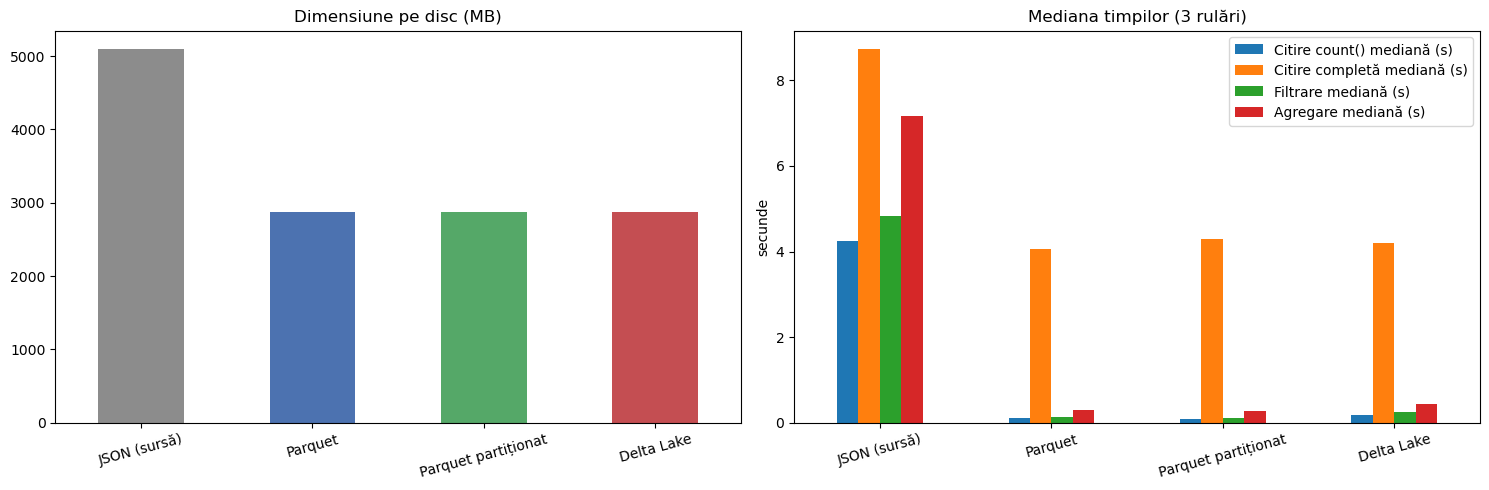

In [53]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
summary["Dimensiune (MB)"].plot.bar(ax=axes[0], color=["#8c8c8c", "#4c72b0", "#55a868", "#c44e52"])
axes[0].set_title("Dimensiune pe disc (MB)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)

time_cols = [c for c in summary.columns if c.endswith("(s)")]
summary[time_cols].plot.bar(ax=axes[1])
axes[1].set_title(f"Mediana timpilor ({REPEATS} rulări)")
axes[1].set_ylabel("secunde")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

In [54]:
s = summary
def ratio(a, b, col):
    return s.loc[a, col] / max(s.loc[b, col], 1e-9)

print("Concluzii generate din valorile măsurate:")
print(f"- Spațiu: Parquet ocupă {s.loc['Parquet', 'Dimensiune (MB)']:,.1f} MB față de "
      f"{s.loc['JSON (sursă)', 'Dimensiune (MB)']:,.1f} MB pentru JSON ({s.loc['Parquet', 'vs sursă (%)']:+.1f}%).")
print(f"- Filtrare: Parquet e de {ratio('JSON (sursă)', 'Parquet', 'Filtrare mediană (s)'):.1f}x mai rapid decât JSON; "
      f"Parquet partiționat e de {ratio('Parquet', 'Parquet partiționat', 'Filtrare mediană (s)'):.1f}x mai rapid decât Parquet nepartiționat.")
print(f"- Agregare: JSON {s.loc['JSON (sursă)', 'Agregare mediană (s)']:.2f} s | Parquet {s.loc['Parquet', 'Agregare mediană (s)']:.2f} s | "
      f"Parquet part. {s.loc['Parquet partiționat', 'Agregare mediană (s)']:.2f} s | Delta {s.loc['Delta Lake', 'Agregare mediană (s)']:.2f} s")
print(f"- Delta vs Parquet partiționat (filtrare): {s.loc['Delta Lake', 'Filtrare mediană (s)']:.2f} s vs "
      f"{s.loc['Parquet partiționat', 'Filtrare mediană (s)']:.2f} s; dimensiune {s.loc['Delta Lake', 'Dimensiune (MB)']:,.1f} vs "
      f"{s.loc['Parquet partiționat', 'Dimensiune (MB)']:,.1f} MB (diferența = _delta_log + fișiere .crc).")
print(f"- Doar Delta Lake oferă istoric: {len(hist_pd)} versiuni (WRITE, APPEND, UPDATE, DELETE) și citirea v0 prin versionAsOf.")

Concluzii generate din valorile măsurate:
- Spațiu: Parquet ocupă 2,876.0 MB față de 5,094.4 MB pentru JSON (-43.5%).
- Filtrare: Parquet e de 34.6x mai rapid decât JSON; Parquet partiționat e de 1.4x mai rapid decât Parquet nepartiționat.
- Agregare: JSON 7.17 s | Parquet 0.29 s | Parquet part. 0.27 s | Delta 0.44 s
- Delta vs Parquet partiționat (filtrare): 0.24 s vs 0.10 s; dimensiune 2,871.3 vs 2,871.5 MB (diferența = _delta_log + fișiere .crc).
- Doar Delta Lake oferă istoric: 4 versiuni (WRITE, APPEND, UPDATE, DELETE) și citirea v0 prin versionAsOf.


## 2. Curățarea transformarea și analiza descriptivă

### Datele de intrare (Delta v0) și raportul de calitate

In [55]:
from pyspark.sql import functions as F, types as T
import pandas as pd

# v0 = scrierea inițială; v1–v3 conțin modificări artificiale (LAB01_*, stars=1, useful+1000)
df_raw = spark.read.format("delta").option("versionAsOf", 0).load(str(DELTA_DIR))

def quality_report(df):
    flag = lambda cond: F.sum(F.when(cond, 1).otherwise(0))
    r = df.agg(
        F.count("*").alias("rânduri"),
        flag(F.col("review_id").isNull()).alias("review_id null"),
        flag(F.col("user_id").isNull()).alias("user_id null"),
        flag(F.col("business_id").isNull()).alias("business_id null"),
        flag(F.col("date").isNull()).alias("date null"),
        flag(F.col("stars").isNull() | ~F.col("stars").isin(1.0, 2.0, 3.0, 4.0, 5.0)).alias("stars invalid"),
        flag((F.col("useful") < 0) | (F.col("funny") < 0) | (F.col("cool") < 0)).alias("voturi negative"),
        flag(F.trim(F.coalesce(F.col("text"), F.lit(""))) == "").alias("text gol"),
        flag((F.year("date") < 2004) | (F.col("date") > F.current_timestamp())).alias("dată în afara intervalului"),
        (F.count("*") - F.countDistinct("review_id")).alias("review_id duplicat"),
    )
    return r.toPandas().T.rename(columns={0: "valoare"})

qr_before = quality_report(df_raw)
qr_before

,valoare
rânduri,6990291
review_id null,147
user_id null,147
business_id null,147
date null,151
stars invalid,147
voturi negative,5
text gol,147
dată în afara intervalului,0
review_id duplicat,147


### Curățare și coloane derivate

In [56]:
df_clean = (
    df_raw
    .dropna(subset=["review_id", "user_id", "business_id", "date", "stars"])
    .filter(F.col("stars").isin(1.0, 2.0, 3.0, 4.0, 5.0))
    .filter((F.col("useful") >= 0) & (F.col("funny") >= 0) & (F.col("cool") >= 0))
    .filter((F.year("date") >= 2004) & (F.col("date") <= F.current_timestamp()))
    .withColumn("text", F.trim("text"))
    .filter(F.length("text") > 0)
    .dropDuplicates(["review_id"])
    # coloane derivate
    .withColumn("text_length", F.length("text"))
    .withColumn("month", F.month("date"))
    .withColumn("total_votes", F.col("useful") + F.col("funny") + F.col("cool"))
    .withColumn("is_positive", F.col("stars") >= 4)
)

qr_after = quality_report(df_clean)
pd.concat([qr_before, qr_after], axis=1, keys=["înainte", "după"])

,înainte,după
,valoare,valoare
rânduri,6990291,6990135
review_id null,147,0
user_id null,147,0
business_id null,147,0
date null,151,0
stars invalid,147,0
voturi negative,5,0
text gol,147,0
dată în afara intervalului,0,0


### Join cu business (+ user pentru DWH) și filtrul

In [58]:
business_schema = T.StructType([
    T.StructField("business_id", T.StringType()), T.StructField("name", T.StringType()),
    T.StructField("city", T.StringType()), T.StructField("state", T.StringType()),
    T.StructField("stars", T.DoubleType()), T.StructField("review_count", T.LongType()),
    T.StructField("is_open", T.IntegerType()), T.StructField("categories", T.StringType()),
])
df_business = (
    spark.read.schema(business_schema).json(str(RAW_DIMS_DIR / "yelp_academic_dataset_business.json"))
    .withColumnRenamed("stars", "business_avg_stars")
    .withColumn("main_category", F.coalesce(F.trim(F.split("categories", ",")[0]), F.lit("Unknown")))
)

df_joined = df_clean.join(
    df_business.select("business_id", "name", "city", "state", "main_category"),
    on="business_id", how="left",
)
n_unmatched = df_joined.filter(F.col("state").isNull()).count()
print(f"Recenzii fără business corespunzător: {n_unmatched:,}")

# Filtru: anul 2022 are doar ~31.6k recenzii (dataset tăiat în ian. 2022) -> distorsionează analiza pe ani
df_processed = df_joined.filter(F.col("year") <= 2021)

Recenzii fără business corespunzător: 0


### Salvarea în data/processed_delta și recitirea

In [59]:
(df_processed.repartition("year")
    .write.format("delta").mode("overwrite").option("overwriteSchema", "true")
    .partitionBy("year").save(str(PROCESSED_DIR)))

processed = spark.read.format("delta").load(str(PROCESSED_DIR))
print(f"Rânduri processed: {processed.count():,}")
processed.printSchema()

Rânduri processed: 6,958,470
root
 |-- business_id: string (nullable = true)
 |-- review_id: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- stars: double (nullable = true)
 |-- useful: long (nullable = true)
 |-- funny: long (nullable = true)
 |-- cool: long (nullable = true)
 |-- text: string (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- year: integer (nullable = true)
 |-- text_length: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- total_votes: long (nullable = true)
 |-- is_positive: boolean (nullable = true)
 |-- name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- state: string (nullable = true)
 |-- main_category: string (nullable = true)



### Agregare + 3 calcule Spark SQL

In [60]:
processed.groupBy("state").agg(
    F.count("*").alias("n_reviews"), F.round(F.avg("stars"), 3).alias("avg_stars")
).orderBy(F.desc("n_reviews")).show(10)

processed.createOrReplaceTempView("reviews")

# 1) Ce categorii primesc cele mai multe recenzii și cum sunt evaluate?
spark.sql("""
  SELECT main_category, COUNT(*) AS n_reviews, ROUND(AVG(stars),3) AS avg_stars
  FROM reviews GROUP BY main_category ORDER BY n_reviews DESC LIMIT 10
""").show(truncate=False)

# 2) Cum evoluează media stelelor și ponderea recenziilor pozitive pe ani?
spark.sql("""
  SELECT year, COUNT(*) AS n, ROUND(AVG(stars),3) AS avg_stars,
         ROUND(AVG(CAST(is_positive AS INT))*100,1) AS pct_positive
  FROM reviews GROUP BY year ORDER BY year
""").show()

# 3) Recenziile lungi sunt considerate mai utile?
spark.sql("""
  SELECT CASE WHEN text_length < 300 THEN '1: <300'
              WHEN text_length < 1000 THEN '2: 300-999'
              ELSE '3: >=1000' END AS len_bucket,
         COUNT(*) AS n, ROUND(AVG(useful),3) AS avg_useful
  FROM reviews GROUP BY 1 ORDER BY 1
""").show()

+-----+---------+---------+
|state|n_reviews|avg_stars|
+-----+---------+---------+
|   PA|  1593681|    3.699|
|   FL|  1154295|    3.762|
|   LA|   758830|    3.881|
|   TN|   611523|    3.761|
|   MO|   500382|    3.734|
|   IN|   487094|    3.789|
|   AZ|   429446|    3.695|
|   NV|   428389|    3.726|
|   CA|   347346|     3.96|
|   NJ|   259762|    3.558|
+-----+---------+---------+
only showing top 10 rows
+----------------------+---------+---------+
|main_category         |n_reviews|avg_stars|
+----------------------+---------+---------+
|Restaurants           |1186444  |3.77     |
|Food                  |350700   |3.879    |
|Nightlife             |229341   |3.741    |
|Bars                  |197587   |3.749    |
|American (Traditional)|175470   |3.661    |
|American (New)        |165591   |3.856    |
|Breakfast & Brunch    |140206   |3.864    |
|Seafood               |126688   |3.835    |
|Sandwiches            |125469   |3.815    |
|Mexican               |119547   |3.757    

### Reprezentare in grafice

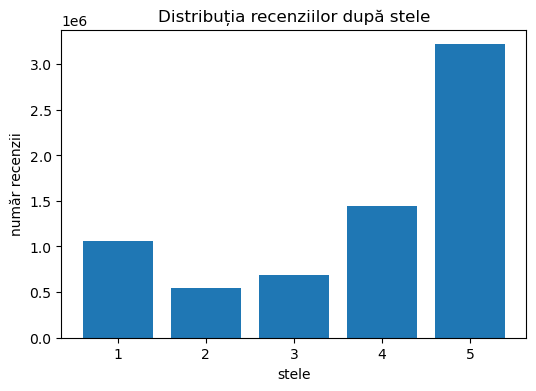

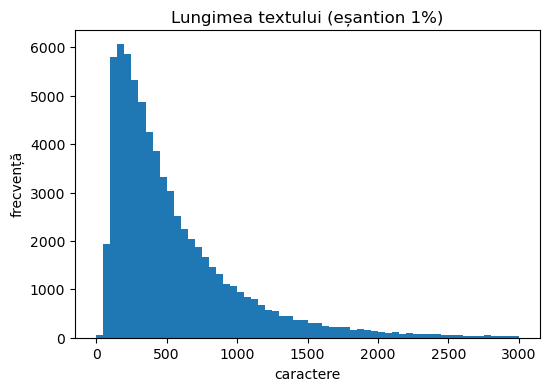

In [61]:
import matplotlib.pyplot as plt

stars_pd = processed.groupBy("stars").count().orderBy("stars").toPandas()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(stars_pd["stars"].astype(int).astype(str), stars_pd["count"])
ax.set(title="Distribuția recenziilor după stele", xlabel="stele", ylabel="număr recenzii")
fig.savefig(FIG_DIR / "stars_distribution.png", dpi=120, bbox_inches="tight"); plt.show()

sample_pd = processed.select("text_length").sample(fraction=0.01, seed=42).toPandas()
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(sample_pd["text_length"], bins=60, range=(0, 3000))
ax.set(title="Lungimea textului (eșantion 1%)", xlabel="caractere", ylabel="frecvență")
fig.savefig(FIG_DIR / "text_length_hist.png", dpi=120, bbox_inches="tight"); plt.show()

## 3. Modelarea DWH și operații OLAP

#### Schema DWH (schemă stea)

Depozitul de date are o **schemă stea**: un tabel de fapte central, `fact_review`, legat de trei tabele de dimensiuni, `dim_date`, `dim_business` și `dim_user`. Tabelele sunt stocate ca **tabele Delta** în `data/dwh/` și sunt interogate prin Spark SQL. Toate sunt construite din datele curățate din `data/processed_delta`.

**Tabelul de fapte: `fact_review`**
- **Granularitate:** un rând = o recenzie Yelp, identificată unic prin `review_id`.
- **Chei străine:** `date_key` → `dim_date`, `business_key` → `dim_business`, `user_key` → `dim_user`.
- **Măsuri:** `stars` (nota, 1–5), `useful`, `funny`, `cool` (voturile primite), `text_length` (lungimea textului, în caractere) și indicatorul `is_positive` (`stars >= 4`).
- Tabelul păstrează și timestamp-ul complet al recenziei, `review_ts`, folosit ca timp al evenimentului în etapa de streaming.
- Este partiționat după `year`, ca filtrările pe perioade să citească doar partițiile necesare.

**Dimensiuni**
- **`dim_date`** (cheie `date_key`, format `yyyyMMdd`): data calendaristică și ierarhia **an → trimestru → lună → zi**, plus ziua săptămânii. Pe această ierarhie se fac roll-up-ul și drill-down-ul temporal. Conține doar datele care apar în recenzii, nu un calendar continuu.
- **`dim_business`** (cheie `business_key`): afacerea evaluată, cu numele, ierarhia geografică **stat → oraș** și categoria principală (`main_category`, prima categorie din lista Yelp).
- **`dim_user`** (cheie `user_key`): autorul recenziei, cu data înscrierii (`yelping_since`), numărul de fani, numărul total de recenzii și media notelor acordate.

**Chei și relații**
- Dimensiunile `dim_business` și `dim_user` au **chei surogat** (`xxhash64` aplicat pe cheia naturală `business_id` / `user_id`). Cheia naturală rămâne în dimensiune ca atribut, iar unicitatea cheilor surogat este verificată explicit.
- Relațiile sunt de tip **N:1** (multe fapte → un membru de dimensiune). De exemplu, o afacere are multe recenzii, dar fiecare recenzie aparține unei singure afaceri.
- Recenziile fără corespondent în `business.json` sau `user.json` sunt legate de un **membru „necunoscut”** (cheia `-1`). Astfel tabelul de fapte nu are referințe fără corespondent și nu se pierd rânduri.

**Metrici calculate prin agregarea faptelor**
- **Numărul de recenzii:** `COUNT(*)`.
- **Media notelor:** `AVG(stars)`.
- **Total voturi utile:** `SUM(useful)`.

Aceste metrici pot fi analizate pe orice combinație de dimensiuni (timp, geografie, categorie, utilizator). Pe ele se bazează operațiile OLAP de mai jos.

```mermaid
erDiagram
    fact_review }o--|| dim_date : date_key
    fact_review }o--|| dim_business : business_key
    fact_review }o--|| dim_user : user_key
    fact_review {
        string review_id
        int date_key FK
        bigint business_key FK
        bigint user_key FK
        timestamp review_ts
        double stars
        bigint useful
        bigint funny
        bigint cool
        int text_length
        boolean is_positive
    }
    dim_date {
        int date_key PK
        date full_date
        int year
        int quarter
        int month
        int day
        int day_of_week
    }
    dim_business {
        bigint business_key PK
        string business_id
        string name
        string city
        string state
        string main_category
    }
    dim_user {
        bigint user_key PK
        string user_id
        timestamp yelping_since
        bigint fans
        bigint review_count
        double average_stars
    }
```

#### Construirea dimensiunilor și a tabelului de fapte

In [63]:
UNKNOWN = -1   # membru "necunoscut" pentru chei fără corespondent -> zero orfani

# dim_business (cheie surogat = hash determinist al cheii naturale)
dim_business = (
    df_business.select(F.xxhash64("business_id").alias("business_key"),
                       "business_id", "name", "city", "state", "main_category")
    .unionByName(spark.createDataFrame(
        [(UNKNOWN, "UNKNOWN", "Unknown", "Unknown", "NA", "Unknown")], dim_business_schema := 
        "business_key long, business_id string, name string, city string, state string, main_category string"))
)

user_schema = T.StructType([
    T.StructField("user_id", T.StringType()), T.StructField("review_count", T.LongType()),
    T.StructField("yelping_since", T.StringType()), T.StructField("fans", T.LongType()),
    T.StructField("average_stars", T.DoubleType()),
])
dim_user = (
    spark.read.schema(user_schema).json(str(RAW_DIMS_DIR / "yelp_academic_dataset_user.json"))
    .select(F.xxhash64("user_id").alias("user_key"), "user_id",
            F.to_timestamp("yelping_since", "yyyy-MM-dd HH:mm:ss").alias("yelping_since"),
            "fans", "review_count", "average_stars")
    .unionByName(spark.createDataFrame(
        [(UNKNOWN, "UNKNOWN", None, 0, 0, None)],
        "user_key long, user_id string, yelping_since timestamp, fans long, review_count long, average_stars double"))
)

dim_date = (
    processed.select(F.to_date("date").alias("full_date")).distinct()
    .select(F.date_format("full_date", "yyyyMMdd").cast("int").alias("date_key"), "full_date",
            F.year("full_date").alias("year"), F.quarter("full_date").alias("quarter"),
            F.month("full_date").alias("month"), F.dayofmonth("full_date").alias("day"),
            F.dayofweek("full_date").alias("day_of_week"))
)

fact_review = (
    processed.select("review_id", "business_id", "user_id", F.col("date").alias("review_ts"),
                     "stars", "useful", "funny", "cool", "text_length", "is_positive", "year")
    .withColumn("date_key", F.date_format("review_ts", "yyyyMMdd").cast("int"))
    .join(dim_business.select("business_id", "business_key"), "business_id", "left")
    .join(dim_user.select("user_id", "user_key"), "user_id", "left")
    .withColumn("business_key", F.coalesce("business_key", F.lit(UNKNOWN).cast("long")))
    .withColumn("user_key", F.coalesce("user_key", F.lit(UNKNOWN).cast("long")))
    .drop("business_id", "user_id")
)

for name, df, part in [("dim_business", dim_business, None), ("dim_user", dim_user, None),
                       ("dim_date", dim_date, None), ("fact_review", fact_review, "year")]:
    w = df.write.format("delta").mode("overwrite").option("overwriteSchema", "true")
    (w.partitionBy(part) if part else w).save(str(DWH_DIR / name))
    spark.read.format("delta").load(str(DWH_DIR / name)).createOrReplaceTempView(name)
    print(f"{name:<13} scris")

dim_business  scris
dim_user      scris
dim_date      scris
fact_review   scris


In [64]:
for t in ["fact_review", "dim_date", "dim_business", "dim_user"]:
    print(t, f"{spark.table(t).count():,}")

fact_review 6,958,470
dim_date 6,017
dim_business 150,347
dim_user 1,987,898


#### Verificări de integritate

In [66]:
checks = {
  "rânduri fact == processed":
      spark.table("fact_review").count() == processed.count(),
  "dim_business: cheie unică":
      spark.sql("SELECT COUNT(*) = COUNT(DISTINCT business_key) FROM dim_business").first()[0],
  "dim_user: cheie unică":
      spark.sql("SELECT COUNT(*) = COUNT(DISTINCT user_key) FROM dim_user").first()[0],
  "dim_date: cheie unică":
      spark.sql("SELECT COUNT(*) = COUNT(DISTINCT date_key) FROM dim_date").first()[0],
  "fact_review: review_id unic":
      spark.sql("SELECT COUNT(*) = COUNT(DISTINCT review_id) FROM fact_review").first()[0],
}
for dim, key in [("dim_date", "date_key"), ("dim_business", "business_key"), ("dim_user", "user_key")]:
    orphans = spark.sql(f"SELECT COUNT(*) FROM fact_review f LEFT ANTI JOIN {dim} d ON f.{key} = d.{key}").first()[0]
    checks[f"orfani fact -> {dim} = 0"] = orphans == 0
n_unknown = spark.sql(f"SELECT COUNT(*) FROM fact_review WHERE business_key={UNKNOWN} OR user_key={UNKNOWN}").first()[0]
print(f"Fapte legate de membrul UNKNOWN: {n_unknown:,}")
pd.Series(checks, name="OK")

Fapte legate de membrul UNKNOWN: 0


rânduri fact == processed          True
dim_business: cheie unică          True
dim_user: cheie unică              True
dim_date: cheie unică              True
fact_review: review_id unic        True
orfani fact -> dim_date = 0        True
orfani fact -> dim_business = 0    True
orfani fact -> dim_user = 0        True
Name: OK, dtype: bool

### Operații OLAP

##### **Operația 1: Roll-up (oraș → stat → total)**

**Întrebare de analiză:** Cum se distribuie recenziile și nota medie când urcăm de la nivel de oraș la nivel de stat și apoi la total? Sunt recenziile concentrate în câteva state sau orașe?

**Operație:** `GROUP BY ROLLUP(state, city)` pe `fact_review` ⋈ `dim_business`. Același query produce trei niveluri de agregare: oraș, subtotal pe stat și total general. Afișăm top 5 state după numărul de recenzii, iar în fiecare stat primele 3 orașe.


In [74]:
# ROLL-UP: recenzii pe stat -> oraș, cu subtotaluri pe stat și total general
olap_rollup = spark.sql("""
WITH r AS (
  SELECT CASE WHEN GROUPING(b.state) = 1 THEN 'TOTAL'
              WHEN GROUPING(b.city)  = 1 THEN 'subtotal stat'
              ELSE 'oraș' END                AS nivel,
         b.state, b.city,
         COUNT(*)                            AS n_reviews,
         ROUND(AVG(f.stars), 3)              AS avg_stars,
         SUM(f.useful)                       AS sum_useful
  FROM fact_review f
  JOIN dim_business b ON f.business_key = b.business_key
  GROUP BY ROLLUP(b.state, b.city)
),
top_states AS (
  SELECT state FROM r WHERE nivel = 'subtotal stat'
  ORDER BY n_reviews DESC LIMIT 5
),
ranked AS (
  SELECT r.*, ROW_NUMBER() OVER (PARTITION BY state, nivel ORDER BY n_reviews DESC) AS rn
  FROM r
)
SELECT nivel, state, city, n_reviews, avg_stars, sum_useful
FROM ranked
WHERE nivel = 'TOTAL'
   OR (state IN (SELECT state FROM top_states) AND (nivel = 'subtotal stat' OR rn <= 3))
ORDER BY CASE WHEN nivel = 'TOTAL' THEN 1 ELSE 0 END,
         state,
         CASE WHEN nivel = 'subtotal stat' THEN 0 ELSE 1 END,
         n_reviews DESC
""")
olap_rollup.toPandas()

,nivel,state,city,n_reviews,avg_stars,sum_useful
0,subtotal stat,FL,None,1154295,3.762,1285182
1,oraș,FL,Tampa,452166,3.754,567034
2,oraș,FL,Clearwater,86913,3.762,87167
3,oraș,FL,Saint Petersburg,78472,3.873,89150
4,subtotal stat,LA,None,758830,3.881,838973
5,oraș,LA,New Orleans,633098,3.945,677949
6,oraș,LA,Metairie,64022,3.606,88041
7,oraș,LA,Kenner,20740,3.240,25146
8,subtotal stat,MO,None,500382,3.734,570866
9,oraș,MO,Saint Louis,252702,3.815,303226


**Interpretare:**
- **Concentrare puternică.** Cele 5 state afișate (PA, FL, LA, TN, MO) adună 4.618.711 din cele 6.958.470 de recenzii, adică **≈66%**. PA este cel mai mare stat, cu 1.593.681 recenzii (≈23% din total).
- **Un oraș dominant în fiecare stat.** Philadelphia are ≈61% din recenziile din PA, New Orleans ≈83% din LA, Nashville ≈74% din TN. Excepție face FL, unde Tampa are doar ≈39%, iar recenziile sunt mai dispersate între orașele din zona Tampa Bay (Clearwater, Saint Petersburg).
- **Nota medie variază mai mult între orașe decât între state.** La nivel de stat, media e între 3,699 (PA) și 3,881 (LA), aproape de media generală de 3,749. În interiorul LA însă, diferențele sunt mari: New Orleans are 3,945, iar Kenner doar 3,240. Agregarea la nivel superior ascunde deci diferențe locale importante.
- **Utilitatea recenziilor.** În PA o recenzie primește în medie ≈1,30 voturi `useful` (2.068.030 / 1.593.681), peste media generală de ≈1,19. În TN media e doar ≈0,92.
- **Problemă de calitate descoperită prin roll-up.** În MO, același oraș apare sub trei denumiri: „Saint Louis”, „St. Louis” și „St Louis”. Luate împreună au 340.682 recenzii (≈68% din MO), dar la nivel de oraș sunt raportate separat. Denumirile orașelor nu sunt normalizate în sursă. Subtotalul pe stat nu e afectat, doar nivelul de oraș.

##### Operatia 2: Drill-down (an → lună, PA)

**Întrebare de analiză:** Cum s-a modificat activitatea de recenzare în Pennsylvania în 2020 față de 2019? Dacă trecem de la nivel de an la nivel de lună, putem vedea când a început scăderea și cât de mult a durat?

**Operație:** Drill-down pe ierarhia temporală din `dim_date`: întâi agregare pe **an**, apoi detaliere pe **lună** pentru 2019 și 2020. Slice-ul fix `state = 'PA'` vine din `dim_business`.

In [77]:
# DRILL-DOWN: din an în lună pentru statul cu cele mai multe recenzii (PA)
# Nivelul 1: an (PA)
olap_drill_year = spark.sql("""
  SELECT d.year,
         COUNT(*)                                        AS n_reviews,
         ROUND(AVG(f.stars), 3)                          AS avg_stars,
         ROUND(AVG(CAST(f.is_positive AS INT)) * 100, 1) AS pct_positive
  FROM fact_review f
  JOIN dim_date d     ON f.date_key = d.date_key
  JOIN dim_business b ON f.business_key = b.business_key
  WHERE b.state = 'PA' AND d.year BETWEEN 2017 AND 2021
  GROUP BY d.year
  ORDER BY d.year
""")
display(olap_drill_year.toPandas())

,year,n_reviews,avg_stars,pct_positive
0,2017,179659,3.732,66.4
1,2018,182964,3.711,65.8
2,2019,180536,3.708,65.6
3,2020,99064,3.718,66.1
4,2021,102950,3.657,64.3


In [78]:
# Nivelul 2: drill-down pe lună, pentru 2019 vs 2020 (PA)
olap_drill_month = spark.sql("""
  SELECT d.month,
         SUM(CASE WHEN d.year = 2019 THEN 1 ELSE 0 END) AS n_2019,
         SUM(CASE WHEN d.year = 2020 THEN 1 ELSE 0 END) AS n_2020,
         ROUND(AVG(CASE WHEN d.year = 2019 THEN f.stars END), 3) AS avg_stars_2019,
         ROUND(AVG(CASE WHEN d.year = 2020 THEN f.stars END), 3) AS avg_stars_2020
  FROM fact_review f
  JOIN dim_date d     ON f.date_key = d.date_key
  JOIN dim_business b ON f.business_key = b.business_key
  WHERE b.state = 'PA' AND d.year IN (2019, 2020)
  GROUP BY d.month
  ORDER BY d.month
""")
display(olap_drill_month.toPandas())

,month,n_2019,n_2020,avg_stars_2019,avg_stars_2020
0,1,15063,13076,3.753,3.717
1,2,14045,12654,3.706,3.721
2,3,15944,8261,3.764,3.775
3,4,14849,4015,3.717,3.707
4,5,16183,5155,3.693,3.631
5,6,16385,6174,3.678,3.630
6,7,16403,8286,3.715,3.679
7,8,16479,9302,3.727,3.715
8,9,15012,8901,3.672,3.680
9,10,13853,8939,3.686,3.710


**Interpretare:**
- **La nivel de an:** în PA, volumul e stabil între 2017 și 2019, la ≈180.000 de recenzii pe an (179.659 → 182.964 → 180.536, variații sub ±2%). În 2020 scade la 99.064, adică **−45,1%** față de 2019. Scăderea e mai mare decât la nivel național (−38,9%, de la 907.284 la 554.557). În 2021 revenirea e minimă: 102.950 recenzii, doar +3,9% față de 2020, și tot cu **−43,0%** sub nivelul din 2019. Nota medie stă între 3,708 și 3,732 în 2017–2020, chiar și în 2020. În 2021 coboară la cel mai mic nivel din perioadă: 3,657, cu 64,3% recenzii pozitive.
- **La nivel de lună se vede când a început scăderea.** În ianuarie și februarie 2020 volumul era aproape normal (−13% și −10% față de 2019). Căderea începe în **martie** (−48%) și atinge minimul în **aprilie**: 4.015 recenzii, față de 14.849, adică **−73%**. Momentul coincide cu restricțiile COVID-19 din martie 2020. Datele arată această coincidență, dar nu dovedesc singure cauza.
- **Revenirea este doar parțială.** Volumul crește până în august (9.302, adică ≈56% din august 2019), apoi scade din nou în noiembrie și decembrie (≈50–57% din nivelul din 2019). Nicio lună din a doua jumătate a lui 2020 nu revine la nivelul din 2019.
- **Volumul scade mult, dar nota medie se schimbă puțin.** În 2019 media lunară rămâne între 3,672 și 3,764. În 2020 cele mai mici valori apar în mai și iunie (≈3,63), iar cele mai mari în noiembrie și decembrie (3,824 și 3,798, adică +0,14 și +0,10 față de aceleași luni din 2019). Media de la final de an e calculată pe mai puține recenzii, deci aceste diferențe trebuie interpretate cu prudență.
- **Ce ascunde nivelul anual.** Agregarea pe an arată doar o scădere de ≈45%. Drill-down-ul arată că 2020 nu a fost uniform: un început normal, o prăbușire bruscă în primăvară și o revenire parțială. Pentru o analiză pe ani, 2020 e o anomalie și nu trebuie tratat ca tendință.

##### Operația 3: Slice (`year = 2019`)

**Întrebare de analiză:** Care au fost cele mai recenzate categorii de afaceri într-un an complet și normal (2019)? Diferă ele prin satisfacția clienților (nota medie, procentul de recenzii pozitive) și prin implicarea lor (voturile `useful`, lungimea textului)?

**Operație:** Slice pe dimensiunea timp. Fixăm o singură valoare, `dim_date.year = 2019`, și analizăm subcubul rezultat pe `dim_business.main_category`. Afișăm top 10 categorii după numărul de recenzii.

In [79]:
# SLICE: o singură valoare pe dimensiunea business -> doar 'Restaurants'
olap_slice = spark.sql("""
  WITH s AS (
    SELECT b.main_category,
           COUNT(*)                                        AS n_reviews,
           ROUND(AVG(f.stars), 3)                          AS avg_stars,
           ROUND(AVG(CAST(f.is_positive AS INT)) * 100, 1) AS pct_positive,
           ROUND(AVG(f.useful), 3)                         AS avg_useful,
           ROUND(AVG(f.text_length), 0)                    AS avg_text_length
    FROM fact_review f
    JOIN dim_date d     ON f.date_key = d.date_key
    JOIN dim_business b ON f.business_key = b.business_key
    WHERE d.year = 2019                      -- SLICE: o singură valoare din dim_date
    GROUP BY b.main_category
  )
  SELECT *,
         ROUND(n_reviews * 100.0 / SUM(n_reviews) OVER (), 2) AS pct_of_2019
  FROM s
  ORDER BY n_reviews DESC
  LIMIT 10
""")
olap_slice.toPandas()

26/10/14 08:42:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/14 08:42:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/14 08:42:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/14 08:42:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/14 08:42:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/14 08:42:51 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/14 0

,main_category,n_reviews,avg_stars,pct_positive,avg_useful,avg_text_length,pct_of_2019
0,Restaurants,151823,3.813,68.3,0.839,491.0,16.73
1,Food,44657,3.899,71.0,1.010,475.0,4.92
2,Nightlife,30868,3.828,68.8,0.961,524.0,3.40
3,Bars,25334,3.783,67.4,0.891,511.0,2.79
4,American (Traditional),22772,3.717,65.3,0.798,511.0,2.51
5,American (New),20964,3.902,70.4,0.759,520.0,2.31
6,Breakfast & Brunch,20122,3.949,72.6,0.786,487.0,2.22
7,Sandwiches,16424,3.870,69.9,0.874,455.0,1.81
8,Seafood,16173,3.905,70.6,0.738,501.0,1.78
9,Beauty & Spas,15994,3.803,68.0,0.778,514.0,1.76


**Interpretare:**
- **Restaurantele domină.** În 2019 au fost 907.284 recenzii, iar **Restaurants** adună 151.823 dintre ele (16,73%). E de peste 3 ori mai mult decât categoria de pe locul 2, **Food** (4,92%). Aproape toate categoriile din top 10 țin de mâncare și băutură. Singura excepție este **Beauty & Spas** (1,76%).
- **Coada lungă.** Primele 10 categorii adună doar ≈40% din recenziile din 2019. Restul de ≈60% se împarte între sute de categorii. O parte din această fragmentare vine din felul în care e construit `main_category`: e prima etichetă din lista Yelp, a cărei ordine nu e garantată. De aceea apar separat categorii care se suprapun, ca Nightlife și Bars sau American (Traditional) și American (New).
- **Satisfacția diferă puțin între categorii.** Nota medie e între 3,717 (**American (Traditional)**, 65,3% recenzii pozitive) și 3,949 (**Breakfast & Brunch**, 72,6% pozitive), deci o diferență de doar ≈0,23 stele. Între categoriile de restaurante, cea „tradițională” este constant cea mai slab evaluată.
- **Implicarea nu urmează nota.** **Food** are cele mai multe voturi utile pe recenzie (1,010), deși nu are cea mai mare notă. **Seafood** și **American (New)** au note mari (≈3,90), dar cele mai puține voturi utile (≈0,74–0,76). Cele mai lungi recenzii sunt în **Nightlife** (524 caractere), iar cele mai scurte în **Sandwiches** (455). Pentru o seară în oraș, clienții scriu recenzii mai detaliate decât pentru un sandviș.
- **Concluzie:** în 2019, volumul de recenzii e concentrat în zona food & beverage, dar calitatea percepută e omogenă. Diferențele dintre categorii se văd mai mult în cât de mult se implică autorii decât în notă.

##### Operatia 4: Dice (timp × geografie × categorie)

**Întrebare de analiză:** În 2020, scăderea recenziilor a fost la fel de mare peste tot? Sau anumite combinații de stat și tip de afacere au fost lovite mai puternic? A afectat scăderea și satisfacția clienților?

**Operație:** Dice. Restrângem cubul simultan pe două dimensiuni:
- `dim_date`: `year IN (2019, 2020)`;
- `dim_business`: `state IN ('PA','FL','LA')` și `main_category IN ('Restaurants','Nightlife','Breakfast & Brunch')`.

Rezultă un subcub de 3 × 3 segmente, comparate între 2019 și 2020.

In [80]:
# DICE: restricții pe mai multe dimensiuni simultan
olap_dice = spark.sql("""
  SELECT b.state,
         b.main_category,
         SUM(CASE WHEN d.year = 2019 THEN 1 ELSE 0 END)          AS n_2019,
         SUM(CASE WHEN d.year = 2020 THEN 1 ELSE 0 END)          AS n_2020,
         ROUND((SUM(CASE WHEN d.year = 2020 THEN 1 ELSE 0 END)
              - SUM(CASE WHEN d.year = 2019 THEN 1 ELSE 0 END)) * 100.0
              / SUM(CASE WHEN d.year = 2019 THEN 1 ELSE 0 END), 1) AS pct_change,
         ROUND(AVG(CASE WHEN d.year = 2019 THEN f.stars END), 3) AS avg_stars_2019,
         ROUND(AVG(CASE WHEN d.year = 2020 THEN f.stars END), 3) AS avg_stars_2020
  FROM fact_review f
  JOIN dim_date d     ON f.date_key = d.date_key
  JOIN dim_business b ON f.business_key = b.business_key
  WHERE d.year IN (2019, 2020)                                          -- dimensiunea 1: timp
    AND b.state IN ('PA', 'FL', 'LA')                                   -- dimensiunea 2: geografie
    AND b.main_category IN ('Restaurants', 'Nightlife', 'Breakfast & Brunch')  -- dimensiunea 2: categorie
  GROUP BY b.state, b.main_category
  ORDER BY pct_change
""")
olap_dice.toPandas()

,state,main_category,n_2019,n_2020,pct_change,avg_stars_2019,avg_stars_2020
0,LA,Breakfast & Brunch,3415,1150,-66.3,4.002,4.087
1,LA,Nightlife,3525,1330,-62.3,3.858,3.896
2,LA,Restaurants,19510,8398,-57.0,3.972,3.970
3,PA,Nightlife,6074,2684,-55.8,3.730,3.782
4,PA,Breakfast & Brunch,4415,2169,-50.9,3.936,3.956
5,PA,Restaurants,32797,18016,-45.1,3.821,3.840
6,FL,Breakfast & Brunch,4422,2515,-43.1,4.068,4.076
7,FL,Nightlife,5804,3384,-41.7,3.915,4.021
8,FL,Restaurants,26367,17768,-32.6,3.804,3.853


**Interpretare:**
- **Toate cele 9 segmente scad, cu intensități foarte diferite.** Pe ansamblul subcubului, recenziile scad de la 106.329 la 57.414 (**−46,0%**). Pe segmente, scăderea merge de la −32,6% (FL, Restaurants) la −66,3% (LA, Breakfast & Brunch). Cel mai afectat segment a scăzut de două ori mai mult decât cel mai puțin afectat.
- **Statul explică cea mai mare parte a diferențelor.** Ordonarea după `pct_change` grupează perfect statele. **LA** are toate cele 3 segmente cele mai afectate (−58,9% pe total). Urmează **PA** (−47,2%), iar **FL** e cel mai puțin afectat (−35,3%). Clasamentul e compatibil cu restricții locale diferite în 2020, de exemplu redeschideri mai rapide în Florida. Datele arată însă doar asocierea, nu cauza.
- **În fiecare stat, Restaurants rezistă cel mai bine.** Pe cele trei state luate împreună, Restaurants scade cu −43,8%. Nightlife (−52,0%) și Breakfast & Brunch (−52,4%) scad mult mai mult. O explicație plauzibilă, nevalidată: restaurantele puteau continua prin livrare și takeaway. Barurile și localurile de brunch depind de prezența fizică a clienților.
- **Satisfacția nu scade odată cu volumul.** În 8 din 9 segmente, nota medie din 2020 e egală sau mai mare decât în 2019. Cea mai mare creștere e la FL Nightlife (+0,106). Singura scădere e neglijabilă: LA Restaurants, −0,002. Clienții care au continuat să scrie recenzii au fost cel puțin la fel de mulțumiți. Este același efect observat la drill-down.
- **Concluzie / decizie:** impactul din 2020 a depins mai mult de **locație** decât de **tipul afacerii**, iar tipul afacerii a contat în același sens în toate statele. Un utilizator al DWH, de exemplu o platformă sau un investitor, ar trebui să evalueze revenirea pe segmente stat × categorie, nu pe medii naționale. Media națională (≈ −39%) ar subestima puternic situația din LA.

### 4. Streaming simulat cu Kafka și MongoDB

In [82]:
STREAM_STATE, STREAM_FROM, STREAM_TO = "PA", "2019-12-01", "2020-01-01"

sample = spark.sql(f"""
  SELECT f.review_id, b.business_id, b.city, b.state, b.main_category,
         f.stars, f.useful, f.text_length,
         date_format(f.review_ts, 'yyyy-MM-dd HH:mm:ss') AS event_time
  FROM fact_review f JOIN dim_business b ON f.business_key = b.business_key
  WHERE b.state = '{STREAM_STATE}'
    AND f.review_ts >= '{STREAM_FROM}' AND f.review_ts < '{STREAM_TO}'
  ORDER BY f.review_ts
""")
sample.coalesce(1).write.mode("overwrite").parquet(str(STREAM_SAMPLE_DIR))
print(f"Eșantion streaming: {spark.read.parquet(str(STREAM_SAMPLE_DIR)).count():,} rânduri "
      f"({STREAM_STATE}, {STREAM_FROM} – {STREAM_TO}, ordonat după event_time)")

Eșantion streaming: 13,351 rânduri (PA, 2019-12-01 – 2020-01-01, ordonat după event_time)


In [91]:
import importlib, subprocess, time, json
from confluent_kafka.admin import AdminClient

scripts_dir = str(PROJECT_ROOT / "scripts")
if scripts_dir not in sys.path:
    sys.path.insert(0, scripts_dir)

import streaming_job
streaming_job = importlib.reload(streaming_job)   # recitește fișierul de pe disc
from streaming_job import start_query

# oprește query-urile vechi (același checkpoint -> conflict)
for q in spark.streams.active:
    print("Opresc query vechi:", q.name)
    q.stop()

print("Topicuri Kafka:", list(AdminClient({"bootstrap.servers": KAFKA_BOOTSTRAP}).list_topics(timeout=10).topics))

query = start_query(spark)
producer_proc = subprocess.Popen(
    [sys.executable, str(PROJECT_ROOT / "scripts" / "producer_kafka.py"),
     "--batch-size", "200", "--pause", "2", "--late-event-after", "5"],
    stdout=open(PROJECT_ROOT / "producer.log", "w"), stderr=subprocess.STDOUT)

Topicuri Kafka: ['yelp_reviews']


26/10/14 09:08:30 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
26/10/14 09:08:31 WARN MicroBatchExecution: Disabling AQE since AQE is not supported in stateful workloads.


[batch 1] 1 ferestre scrise în MongoDB
[batch 2] 2 ferestre scrise în MongoDB
[batch 3] 2 ferestre scrise în MongoDB
[batch 4] 3 ferestre scrise în MongoDB
[batch 5] 2 ferestre scrise în MongoDB
[batch 6] 2 ferestre scrise în MongoDB
[batch 7] 2 ferestre scrise în MongoDB
[batch 8] 2 ferestre scrise în MongoDB
[batch 9] 3 ferestre scrise în MongoDB
[batch 10] 2 ferestre scrise în MongoDB
[batch 11] 2 ferestre scrise în MongoDB
[batch 12] 2 ferestre scrise în MongoDB
[batch 13] 2 ferestre scrise în MongoDB
[batch 14] 2 ferestre scrise în MongoDB
[batch 15] 2 ferestre scrise în MongoDB
[batch 16] 3 ferestre scrise în MongoDB
[batch 17] 2 ferestre scrise în MongoDB
[batch 18] 2 ferestre scrise în MongoDB
[batch 19] 2 ferestre scrise în MongoDB
[batch 20] 2 ferestre scrise în MongoDB
[batch 21] 3 ferestre scrise în MongoDB
[batch 22] 2 ferestre scrise în MongoDB
[batch 23] 3 ferestre scrise în MongoDB
[batch 24] 1 ferestre scrise în MongoDB
[batch 25] 2 ferestre scrise în MongoDB
[batch 26

In [92]:
time.sleep(60) # lasam fluxul să proceseze câteva loturi
print(query.status)
print(json.dumps(query.lastProgress, indent=1, default=str)[:1500])

{'message': 'Waiting for next trigger', 'isDataAvailable': True, 'isTriggerActive': False}
{
 "id": "d5081514-9791-4cde-a015-03a12b120217",
 "runId": "e99157c7-5299-4d0e-9a6a-51e9d250d3dd",
 "name": "yelp_window_agg",
 "timestamp": "2026-10-14T09:10:45.000Z",
 "batchId": 27,
 "batchDuration": 1367,
 "durationMs": {
  "addBatch": 1311,
  "commitOffsets": 19,
  "getBatch": 0,
  "latestOffset": 6,
  "queryPlanning": 8,
  "triggerExecution": 1367,
  "walCommit": 20
 },
 "eventTime": {
  "avg": "2019-12-31T04:28:22.556Z",
  "max": "2019-12-31T19:01:58.000Z",
  "min": "2019-12-30T17:21:16.000Z",
  "watermark": "2019-12-28T17:20:36.000Z"
 },
 "stateOperators": [
  {
   "operatorName": "stateStoreSave",
   "numRowsTotal": 4,
   "numRowsUpdated": 2,
   "numRowsRemoved": 1,
   "allUpdatesTimeMs": 195,
   "allRemovalsTimeMs": 24,
   "commitTimeMs": 4582,
   "memoryUsedBytes": 29984,
   "numRowsDroppedByWatermark": 0,
   "numShufflePartitions": 64,
   "numStateStoreInstances": 64,
   "customMetric

In [93]:
# Exemplu de mesaj din Kafka
from confluent_kafka import Consumer
c = Consumer({"bootstrap.servers": KAFKA_BOOTSTRAP, "group.id": "notebook-peek",
              "auto.offset.reset": "earliest", "enable.auto.commit": False})
c.subscribe([KAFKA_TOPIC])
msg = None
for _ in range(20):
    msg = c.poll(1.0)
    if msg and not msg.error():
        break
c.close()
print("key:", msg.key().decode(), "\nvalue:", json.dumps(json.loads(msg.value()), indent=1))

key: 5DShxdF_W2vbwpni3bxrSQ 
value: {
 "review_id": "Fi8mL4XZT3W9bCeKX_0KrQ",
 "business_id": "5DShxdF_W2vbwpni3bxrSQ",
 "city": "Spring House",
 "state": "PA",
 "main_category": "Barre Classes",
 "stars": 3.0,
 "useful": 1,
 "text_length": 745,
 "event_time": "2019-12-01 00:05:09",
 "ingest_time": "2026-10-14 09:08:33"
}


,window_start,avg_stars,batch_id,n_reviews,sum_useful,updated_at,window_end
0,2019-12-01,3.766,2,474,409,2026-10-14 09:08:41.483,2019-12-02
1,2019-12-02,3.722,3,403,460,2026-10-14 09:08:46.343,2019-12-03
2,2019-12-03,3.879,4,380,420,2026-10-14 09:08:51.397,2019-12-04
3,2019-12-04,3.712,4,389,414,2026-10-14 09:08:51.397,2019-12-05
4,2019-12-05,3.688,5,401,451,2026-10-14 09:08:56.313,2019-12-06
5,2019-12-06,3.655,6,403,523,2026-10-14 09:09:01.351,2019-12-07
6,2019-12-07,3.613,7,452,455,2026-10-14 09:09:06.437,2019-12-08
7,2019-12-08,3.676,8,494,429,2026-10-14 09:09:11.320,2019-12-09
8,2019-12-09,3.651,9,453,461,2026-10-14 09:09:16.341,2019-12-10
9,2019-12-10,3.492,9,321,384,2026-10-14 09:09:16.341,2019-12-11


Ferestre în MongoDB: 31


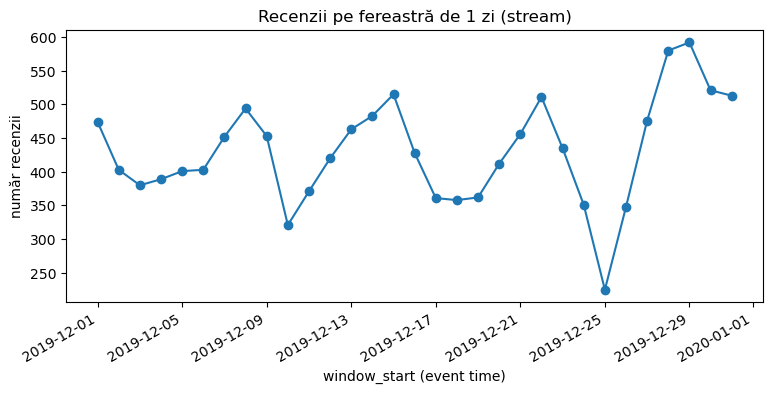

In [94]:
# Documente din MongoDB + grafic linie
from pymongo import MongoClient
with MongoClient(MONGO_URI) as client:
    docs = list(client[MONGO_DB][MONGO_COLL].find({}, {"_id": 0}).sort("window_start", 1))
win_pd = pd.DataFrame(docs)
display(win_pd.head(10))
print(f"Ferestre în MongoDB: {len(win_pd)}")
assert len(win_pd) >= 3

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(win_pd["window_start"], win_pd["n_reviews"], marker="o")
ax.set(title=f"Recenzii pe fereastră de {WINDOW if 'WINDOW' in dir() else '1 zi'} (stream)",
       xlabel="window_start (event time)", ylabel="număr recenzii")
fig.autofmt_xdate(); fig.savefig(FIG_DIR / "stream_windows.png", dpi=120, bbox_inches="tight"); plt.show()

In [96]:
# producer_proc.wait(timeout=600)
producer_proc.terminate()
query.stop()

---

In [ ]:
spark.stop()